# Lab 3 - SVM Overlapping Data (Soft Margin Tuning)
## JS06 - Classification 2

**Name:** Tiara Febrianie  
**NIM:** 244107020097  

### Objective
Understand the concept of soft margins in SVM when dealing with noisy or overlapping datasets, and analyze the effect of the hyperparameter $C$ on the trade-off between margin width and classification errors.

## Step 1 - Import Libraries and Create Plotting Function

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

sns.set_theme(style='whitegrid')
%matplotlib inline

def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # create a grid for model evaluation
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X_grid = np.meshgrid(y, x)
    xy = np.vstack([X_grid.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)
    
    # plot boundary and margins
    ax.contour(X_grid, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])
    
    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, edgecolors='k', facecolors='none')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

## Step 2 - Create Dummy Data with Overlap
Generate data with a larger standard deviation (`cluster_std=1.2`) causing the two classes to overlap.

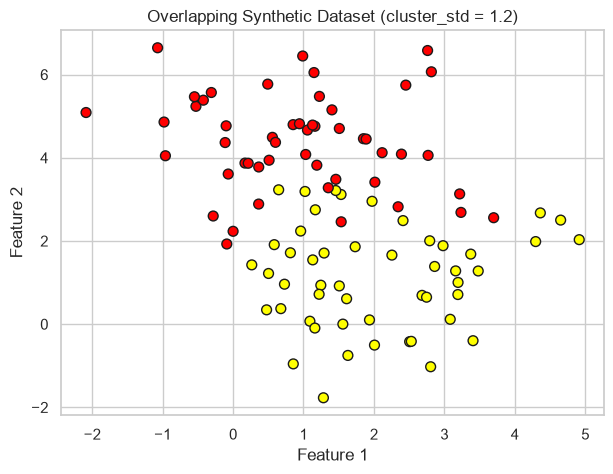

In [2]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn', edgecolors='k')
plt.title('Overlapping Synthetic Dataset (cluster_std = 1.2)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

## Step 3 - Analyze the Impact of Tuning Parameter $C$
- **Large $C$ (e.g. $C=10.0$):** Harder margin, penalizes misclassifications heavily, leading to narrower margins and fewer margin violations.
- **Small $C$ (e.g. $C=0.1$):** Softer margin, allows more points into or across the margin, leading to wider margins and better generalization.

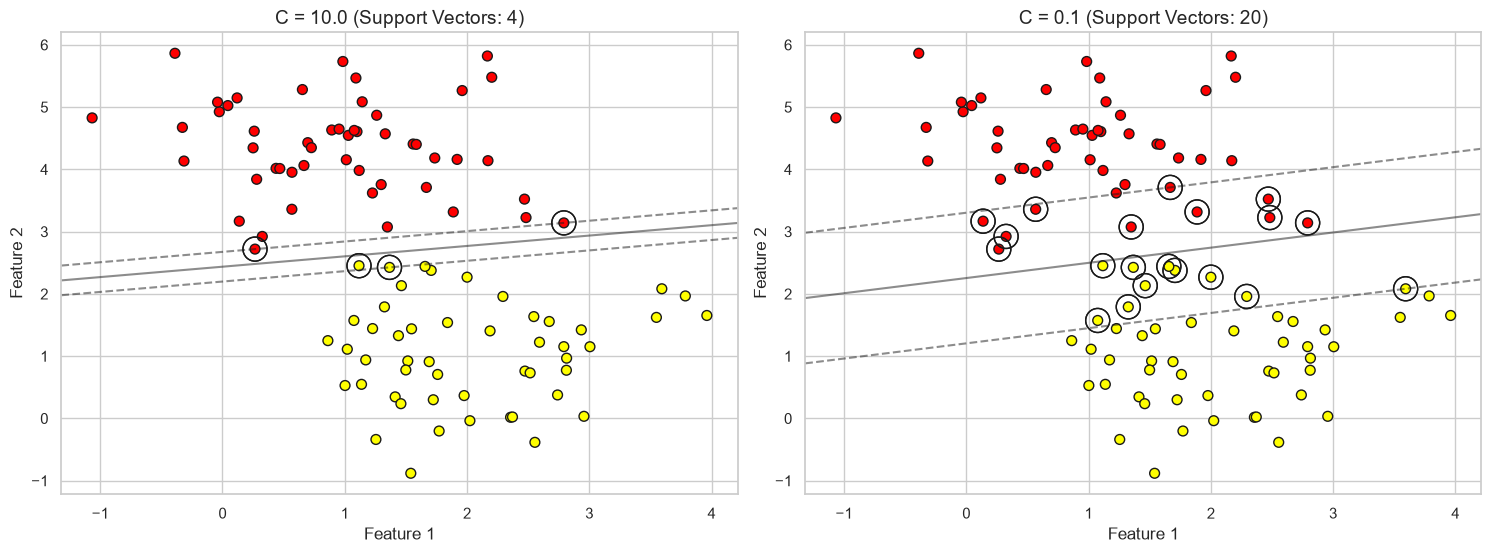

In [3]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn', edgecolors='k')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, edgecolors='k', facecolors='none')
    axi.set_title('C = {0:.1f} (Support Vectors: {1})'.format(C, len(model.support_vectors_)), size=14)
    axi.set_xlabel('Feature 1')
    axi.set_ylabel('Feature 2')

plt.show()